# 8.4.2 — Mô hình dự báo trễ chuyến bay FAA ≥ 15 phút (SkyOps DSS)

**Bài toán.** Phân loại nhị phân: chuyến bay có hạ cánh trễ ≥ 15 phút so với lịch CRS hay không (định nghĩa FAA/BTS).
Kết quả là cột `Delay_Probability` (0.00–1.00) cho **toàn bộ 1.151.344 chuyến**, nạp vào **Power BI Desktop – Trang 5**.

**Giao thức (cố định trước khi xem tập test):**

| Hạng mục | Quy ước |
|---|---|
| Thời điểm dự báo | `T_pred = CRS_DEP − 60 phút` (DSS tác nghiệp cho trung tâm điều hành OCC) |
| Anti-Data Leakage | Mọi biến phải **đã biết tại `T_pred`**: lịch CRS, lịch sử ≤ D-1, lịch sử tàu bay (chặng inbound), trạng thái sân bay/mạng lưới trước `T_pred`. Cấm mọi biến hậu sự kiện của chính chuyến bay. |
| Chia tập theo thời gian | Train 01/2022–04/2023 · Validation 05–06/2023 · Test 07–08/2023 |
| Chọn mô hình | Chỉ theo **validation**; test chỉ dùng để báo cáo |
| Mô hình | Ensemble XGBoost (GPU) + LightGBM → hiệu chỉnh Isotonic |
| Hạ tầng | Google Colab GPU (free T4) hoặc cụm Velura RTX 4060; seed 42 |

Notebook gọi đúng mã nguồn trong `ml/delay_8_4/src` (repo `bi-dss-platform`) nên kết quả trùng với pipeline dòng lệnh `run_pipeline.py`.

## 0. Cấu hình môi trường

In [1]:
# Tham so (papermill co the ghi de) -----------------------------------------
FORCE_REBUILD = True          # True: dung lai toan bo feature tu warehouse.duckdb (full cycle)
AUDIT_SAMPLE = 400            # so chuyen kiem tra leakage doc lap
REPO_URL = "https://github.com/Royal2005-coder/bi-dss-platform.git"
DRIVE_DIR = "/content/drive/MyDrive/SkyOps_8_4"   # Colab: thu muc chua warehouse.duckdb, nhan CSV

In [2]:
# Parameters
FORCE_REBUILD = True


In [3]:
import os, sys, subprocess, json, time, platform, hashlib, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/bi-dss-platform").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/bi-dss-platform"], check=True)
    ML_DIR = Path("/content/bi-dss-platform/ml/delay_8_4")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ML_DIR / "requirements.txt")], check=True)
    DB_PATH = Path(DRIVE_DIR) / "warehouse.duckdb"
else:
    ML_DIR = Path.cwd().parent if (Path.cwd().parent / "run_pipeline.py").exists() else Path.cwd()
    DB_PATH = Path(os.environ.get("BI_DUCKDB_PATH", ML_DIR / "data" / "warehouse.duckdb"))
WORK_DIR, OUT_DIR = ML_DIR / "work", ML_DIR / "outputs"
sys.path.insert(0, str(ML_DIR / "src"))
os.environ.update(BI_DUCKDB_PATH=str(DB_PATH), BI_WORK_DIR=str(WORK_DIR), BI_OUT_DIR=str(OUT_DIR),
                  BI_FEATURE_SPEC=str(OUT_DIR / "models" / "feature_spec_v14.json"))
print("ML_DIR :", ML_DIR)
print("DB     :", DB_PATH, "exists =", DB_PATH.exists(), f"({DB_PATH.stat().st_size/1e6:.0f} MB)" if DB_PATH.exists() else "")
print("Python :", platform.python_version(), "|", platform.platform())

ML_DIR : /home/ai1/bi-dss/rnd_8_4/delay_8_4
DB     : /home/ai1/bi-dss/rnd_8_4/delay_8_4/data/warehouse.duckdb exists = True (569 MB)
Python : 3.11.18 | Linux-5.15.0-139-generic-x86_64-with-glibc2.31


In [4]:
# GPU: Colab T4 / Velura RTX 4060. XGBoost dung device='cuda'; LightGBM chay CPU da luong.
import xgboost as xgb, lightgbm as lgb, sklearn, duckdb, numpy as np, pandas as pd
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv"],
                     capture_output=True, text=True).stdout or "Khong thay GPU NVIDIA -> chay CPU")
try:
    xgb.train({"tree_method": "hist", "device": "cuda"}, xgb.DMatrix(np.zeros((4, 1)), label=[0, 1, 0, 1]), 1)
    print("XGBoost CUDA: OK")
except Exception as e:
    print("XGBoost CUDA khong kha dung:", e)
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| sklearn", sklearn.__version__, "| duckdb", duckdb.__version__)

name, memory.total [MiB], memory.used [MiB]
NVIDIA GeForce RTX 4060, 8188 MiB, 3922 MiB

XGBoost CUDA: OK
xgboost 3.2.0 | lightgbm 4.7.0 | sklearn 1.9.1 | duckdb 2.0.0


In [5]:
def run_step(*args):
    """Chay run_pipeline.py va in log theo thoi gian thuc."""
    cmd = [sys.executable, "-u", str(ML_DIR / "run_pipeline.py"), "--db", str(DB_PATH),
           "--work", str(WORK_DIR), "--out", str(OUT_DIR), *args]
    t0 = time.time()
    with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                          encoding="utf-8", errors="replace", env=dict(os.environ, PYTHONIOENCODING="utf-8")) as p:
        for line in p.stdout:
            if "val-auc" in line or "valid_0" in line:
                continue  # bo bot log tung vong boosting
            print(line, end="")
    print(f"-> exit {p.returncode} sau {time.time()-t0:.0f}s")
    assert p.returncode == 0, "pipeline loi"

## 1. Dữ liệu nguồn (kho DuckDB của mục 8.1)

Nguồn: `flights_sample_3m.csv` (BTS, mẫu ngẫu nhiên ~10% các chuyến nội địa Mỹ) → dbt-duckdb → `marts.fact_flight` (1.151.344 chuyến, 01/2022–08/2023).
Biến mục tiêu `target = is_arr_delayed15` chỉ xác định với chuyến **hoàn thành** (không hủy/chuyển hướng); chuyến hủy vẫn được chấm điểm vì tại `T_pred` chưa ai biết nó sẽ bị hủy.

In [6]:
con = duckdb.connect(str(DB_PATH), read_only=True)
overview = con.execute("""
    SELECT CASE WHEN date_key <= 20230430 THEN '1-train' WHEN date_key <= 20230630 THEN '2-validation' ELSE '3-test' END AS split,
           MIN(date_key) AS tu_ngay, MAX(date_key) AS den_ngay, COUNT(*) AS so_chuyen,
           SUM(is_completed) AS hoan_thanh, ROUND(AVG(CASE WHEN is_completed = 1 THEN is_arr_delayed15 END), 4) AS ty_le_tre15
    FROM marts.fact_flight GROUP BY 1 ORDER BY 1""").fetchdf()
con.close()
overview

,split,tu_ngay,den_ngay,so_chuyen,hoan_thanh,ty_le_tre15
0,1-train,20220101,20230430,910505,886032.0,0.2131
1,2-validation,20230501,20230630,118115,116224.0,0.2237
2,3-test,20230701,20230831,122724,119920.0,0.2526


## 2. Feature engineering tiền sự kiện (DuckDB / Python)

| Nhóm | Ví dụ | Mốc thời gian được phép |
|---|---|---|
| Lịch CRS & lịch sử ≤ D-1 | giờ cất cánh KH, khoảng cách, mật độ lịch, tỷ lệ trễ trước đó theo hãng/tuyến/sân bay/giờ (cửa sổ kết thúc ở `1 PRECEDING`) | trước ngày bay |
| Thời tiết ngày bay | mưa, gió giật, tầm nhìn, mã thời tiết tại sân bay đi/đến (Open-Meteo) | dự báo ngày (proxy) |
| Lịch sử tàu bay (proxy) | chặng inbound cùng hãng + số hiệu: thời gian quay đầu KH, độ trễ đã biết, cận dưới độ trễ | sự kiện đã xảy ra trước `T_pred` |
| Nowcast sân bay | số chuyến đã cất cánh, trễ TB, backlog, hủy tại sân bay đi/đến trong 60–180 phút | ≤ `T_pred` (giờ địa phương) |
| Nowcast mạng lưới | tỷ lệ trễ toàn quốc / theo hãng / vùng / hãng×vùng trong 60–720 phút | ≤ `T_pred` (đồng hồ **UTC**, múi giờ IANA) |

Bước 1–4 của pipeline:

In [7]:
# Buoc 1-4: feature tien su kien. FORCE_REBUILD=True -> dung lai tu warehouse.duckdb (full cycle).
run_step("--from-step", "1", "--to-step", "4", *(["--force"] if FORCE_REBUILD else []))

[run ] step 1 features_base


wrote /home/ai1/bi-dss/rnd_8_4/delay_8_4/work/features.parquet (1151344, 86) labelled 1122174
[done] step 1 features_base in 12s
[run ] step 2 features_v8


cached /home/ai1/bi-dss/rnd_8_4/delay_8_4/work/features_v8.parquet (1151344, 171)
[done] step 2 features_v8 in 8s
[run ] step 3 nowcast_h60


wrote /home/ai1/bi-dss/rnd_8_4/delay_8_4/work/nowcast_h60.parquet rows=1151344 has_inbound=0.020 inbound_known=0.969 H=60 in 2.0s
[done] step 3 nowcast_h60 in 2s
[run ] step 4 network_h60


tz cross-check vs CRS_ARR: 0.9999 exact match


wrote /home/ai1/bi-dss/rnd_8_4/delay_8_4/work/network_h60_v2.parquet rows=1151344 mean nat_dep_n_120=185.1 car_dep_n_120=20.1 H=60 in 9.8s


[done] step 4 network_h60 in 10s
-> exit 0 sau 32s


In [8]:
f8 = pd.read_parquet(WORK_DIR / "features_v8.parquet", columns=["flight_key", "date_key", "target"])
nc = pd.read_parquet(WORK_DIR / "nowcast_h60.parquet")
net = pd.read_parquet(WORK_DIR / "network_h60_v2.parquet")
print(f"features_v8: {f8.shape} | nowcast_h60: {nc.shape} | network_h60: {net.shape}")
print(f"Ty le chuyen co chang inbound cung so hieu (proxy tau bay): {nc.has_inbound.mean():.3%}"
      "  <- thap vi du lieu la mau ~10% nen chuoi quay vong bi dut")
print(f"So chuyen toan quoc da cat canh trong 120' truoc T_pred (TB): {net.nat_dep_n_120.mean():.0f}; theo hang: {net.car_dep_n_120.mean():.1f}")
net.describe().T[["mean", "std", "min", "max"]].head(12)

features_v8: (1151344, 3) | nowcast_h60: (1151344, 25) | network_h60: (1151344, 101)
Ty le chuyen co chang inbound cung so hieu (proxy tau bay): 1.955%  <- thap vi du lieu la mau ~10% nen chuoi quay vong bi dut
So chuyen toan quoc da cat canh trong 120' truoc T_pred (TB): 185; theo hang: 20.1


,mean,std,min,max
flight_key,575672.500000,332364.528502,1.000000,1.151344e+06
nat_dep_n_60,94.568993,29.873943,0.000000,2.070000e+02
nat_dep_mean_60,11.582430,14.903715,-29.000000,4.650000e+02
nat_dep_r15_60,0.196620,0.138761,0.000000,1.000000e+00
nat_dep_n_120,185.105469,61.519070,0.000000,3.150000e+02
nat_dep_mean_120,11.187387,12.826289,-11.000000,2.525000e+02
nat_dep_r15_120,0.191991,0.129973,0.000000,1.000000e+00
nat_dep_n_360,499.504395,200.616821,0.000000,7.720000e+02
nat_dep_mean_360,10.831879,11.343656,-5.258883,1.274677e+02
nat_dep_r15_360,0.181785,0.114729,0.000000,8.145695e-01


## 3. R&D có kiểm soát — vì sao chọn kiến trúc này

Ablation: cùng learner (XGBoost GPU), cùng seed và cùng split; **chỉ thay đổi nhóm biến**, nên chênh lệch AUC quy được cho nhóm biến đó.
Các bước chọn đều dựa trên validation; test được ghi lại để minh bạch.

In [9]:
rnd = ML_DIR / "reports" / "rnd"
a = json.load(open(rnd / "experiment_v11_ablation.json")); n = json.load(open(rnd / "experiment_v12_network_h60.json"))
t = json.load(open(rnd / "experiment_v13_hl180.json")); base = json.load(open(rnd / "baseline_v10_model_comparison.json"))
rows = [("v10 (bàn giao cũ) LGBM+XGB rank", base["ensemble_rank_normalized"]["val"]["auc"], base["ensemble_rank_normalized"]["test"]["auc"], "D-1, ensemble theo thứ hạng")]
lab = {"A0_D-1_strict": "A0 · CRS + lịch sử ≤ D-1", "A1_D-1_weather": "A1 · + thời tiết ngày bay",
       "B1_T-60_aircraft": "B1 · + lịch sử tàu bay (inbound) @T-60", "B2_T-60_full": "B2 · + nowcast sân bay @T-60",
       "B1_T-120_aircraft": "B1 @T-120", "B2_T-120_full": "B2 @T-120"}
for k, v in lab.items():
    rows.append((v, a[k]["val_auc"], a[k]["test_auc"], f"{a[k]['n_feat']} biến"))
rows.append(("B3 · + nowcast mạng lưới (UTC)", n["B3_T-60_network"]["val_auc"], n["B3_T-60_network"]["test_auc"], f"{n['B3_T-60_network']['n_feat']} biến"))
for k, v in [("C1_xgb", "C1 · mạng lưới v2 (hãng×vùng, 60–720')"), ("C2_xgb_recency", "C2 · + trọng số gần đây (loại)"),
             ("L_lgb", "LightGBM cùng bộ biến"), ("E_rank_avg", "Ensemble XGB + LGBM")]:
    rows.append((v, t[k]["val"]["auc"], t[k]["test"]["auc"], ""))
abl = pd.DataFrame(rows, columns=["Thí nghiệm", "Val AUC", "Test AUC", "Ghi chú"]).round(4)
abl

,Thí nghiệm,Val AUC,Test AUC,Ghi chú
0,v10 (bàn giao cũ) LGBM+XGB rank,0.7364,0.7280,"D-1, ensemble theo thứ hạng"
1,A0 · CRS + lịch sử ≤ D-1,0.7203,0.7097,132 biến
2,A1 · + thời tiết ngày bay,0.7355,0.7269,156 biến
3,B1 · + lịch sử tàu bay (inbound) @T-60,0.7374,0.7296,163 biến
4,B2 · + nowcast sân bay @T-60,0.7459,0.7365,180 biến
5,B1 @T-120,0.7367,0.7288,163 biến
6,B2 @T-120,0.7430,0.7336,180 biến
7,B3 · + nowcast mạng lưới (UTC),0.7492,0.7395,219 biến
8,"C1 · mạng lưới v2 (hãng×vùng, 60–720')",0.7496,0.7401,
9,C2 · + trọng số gần đây (loại),0.7484,0.7394,


## 4. Huấn luyện mô hình cuối (v14) trên GPU

- **Stage 1 (chọn):** XGBoost GPU (siêu tham số tốt nhất từ random search trên validation) + LightGBM, early stopping trên validation; trung bình xác suất → **Isotonic** (fit trên validation) → ngưỡng tối ưu F1 trên validation.
- **Stage 2 (triển khai):** refit trên train + validation với số vòng × 1,15; giữ nguyên bộ hiệu chỉnh và ngưỡng của stage 1.
- Sửa look-ahead: quy mô hub sân bay tính lại chỉ trên kỳ train.

In [10]:
run_step("--from-step", "5", "--to-step", "5")

[run ] step 5 train_final_v14


[22:38:02] device=cuda xgb=3.2.0 lgb=4.7.0 sklearn=1.9.1


[22:38:08] rows=1151344 labelled=1122174 train=886031 val=116223 test=119920 features=280


[22:42:07] stage1 val AUC=0.7523 test AUC=0.7416 thr=0.25


[22:46:12] stage2 test AUC=0.7443 CI95=[0.7412566305773519, 0.7473425847183136]


[22:46:46] wrote /home/ai1/bi-dss/rnd_8_4/delay_8_4/outputs/DSS_Flight_Prediction.csv rows=1151344 prob range=[0.0010,0.9990]


[22:46:47] DONE in 524s


[done] step 5 train_final_v14 in 526s
-> exit 0 sau 526s


In [11]:
S = json.load(open(OUT_DIR / "model_summary_v14.json", encoding="utf-8"))
s1, s2 = S["stage1_selection"], S["stage2_production"]
def row(name, m): return {"Mô hình": name, "ROC-AUC": m["auc"], "PR-AUC": m["ap"], "Brier": m["brier"], "Ngưỡng": m["threshold"],
                          "Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"], "Accuracy": m["accuracy"],
                          "TN": m["tn"], "FP": m["fp"], "FN": m["fn"], "TP": m["tp"]}
res = pd.DataFrame([row("Stage 1 · Validation", s1["val"]), row("Stage 1 · Test", s1["test"]),
                    row("Stage 2 (triển khai) · Test", s2["test"]), row("Stage 2 · Test @0.5", s2["test_at_0.5"])]).round(4)
print("Test AUC stage 2 - CI95 bootstrap:", [round(x, 4) for x in s2["test_auc_ci95"]])
print("AUC theo thang (test):", {k: round(v, 4) for k, v in S["test_auc_by_month"].items()})
res

Test AUC stage 2 - CI95 bootstrap: [0.7413, 0.7473]
AUC theo thang (test): {'7': 0.7515, '8': 0.7276}


,Mô hình,ROC-AUC,PR-AUC,Brier,Ngưỡng,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
0,Stage 1 · Validation,0.7523,0.4896,0.1459,0.25,0.4245,0.6052,0.4990,0.7281,68884,21336,10267,15736
1,Stage 1 · Test,0.7416,0.5106,0.1597,0.25,0.4217,0.6673,0.5168,0.6848,61906,27724,10076,20214
2,Stage 2 (triển khai) · Test,0.7443,0.5146,0.1594,0.25,0.4130,0.6925,0.5174,0.6738,59824,29806,9315,20975
3,Stage 2 · Test @0.5,0.7443,0.5146,0.1594,0.50,0.6106,0.2893,0.3926,0.7739,84042,5588,21527,8763


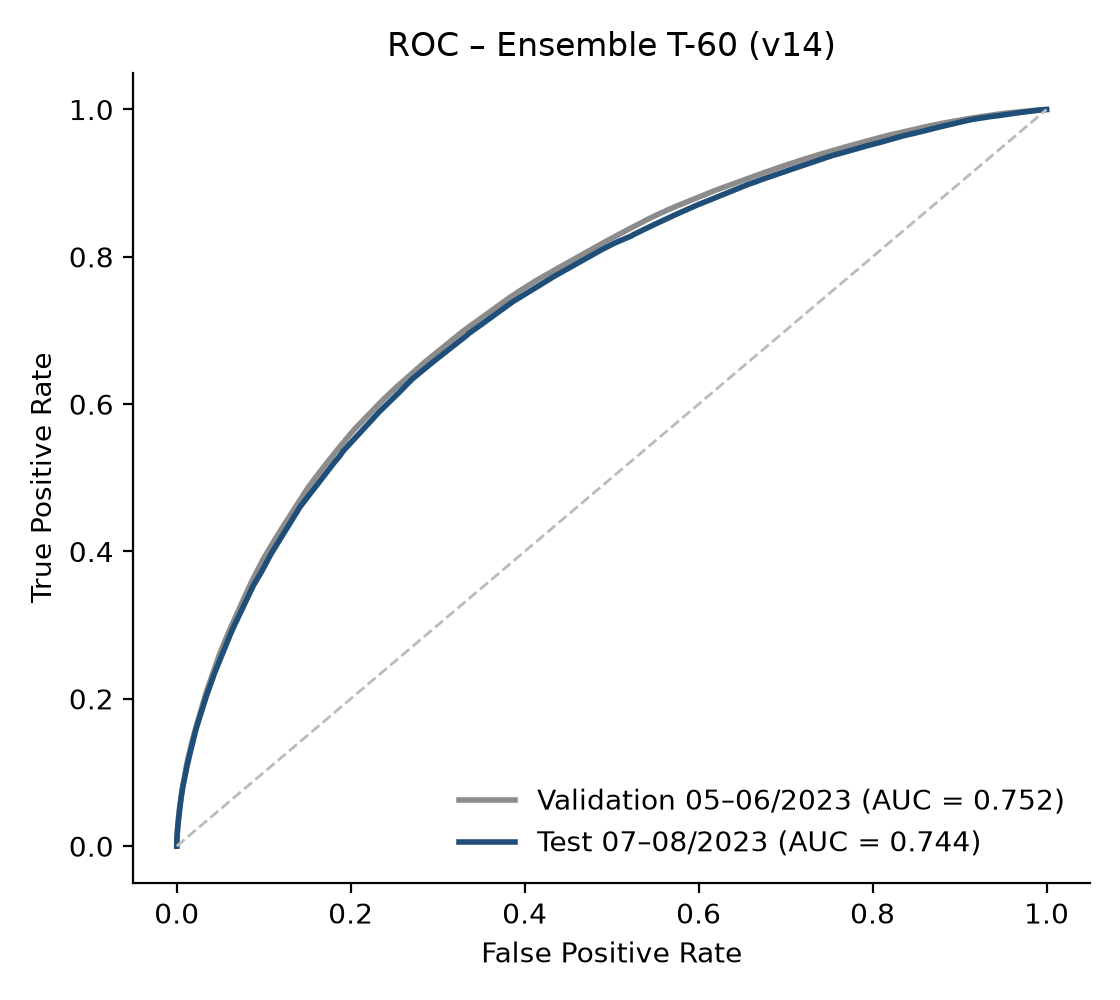

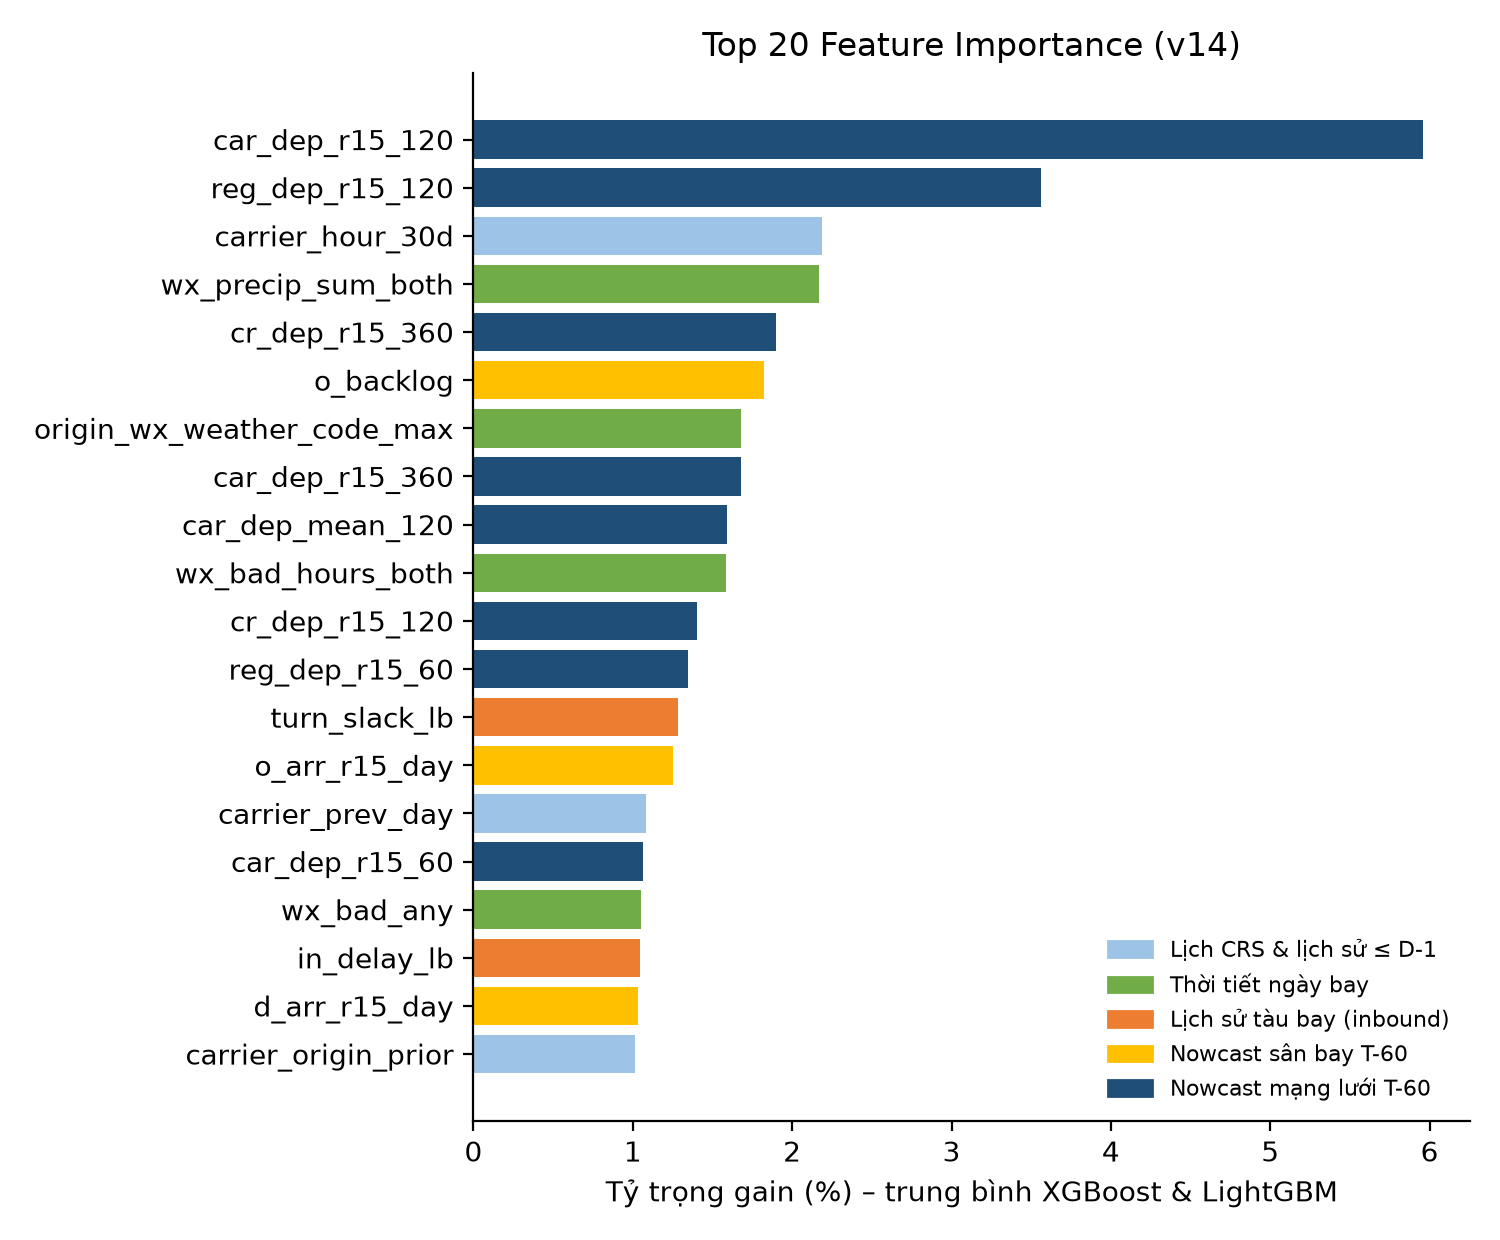

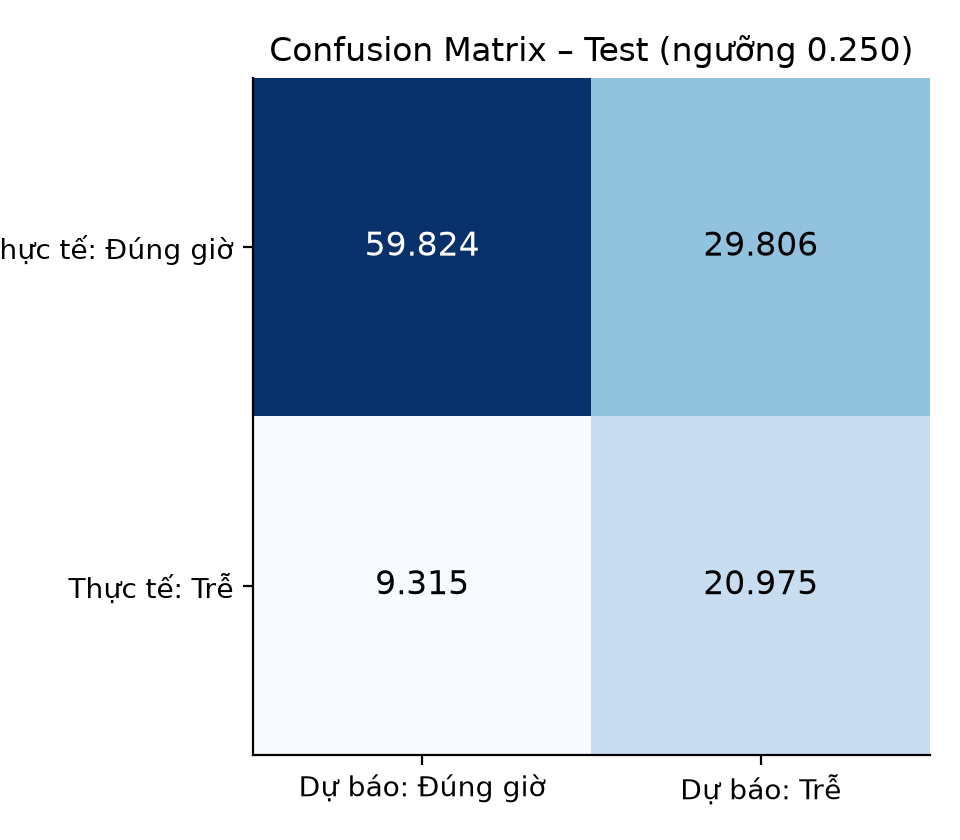

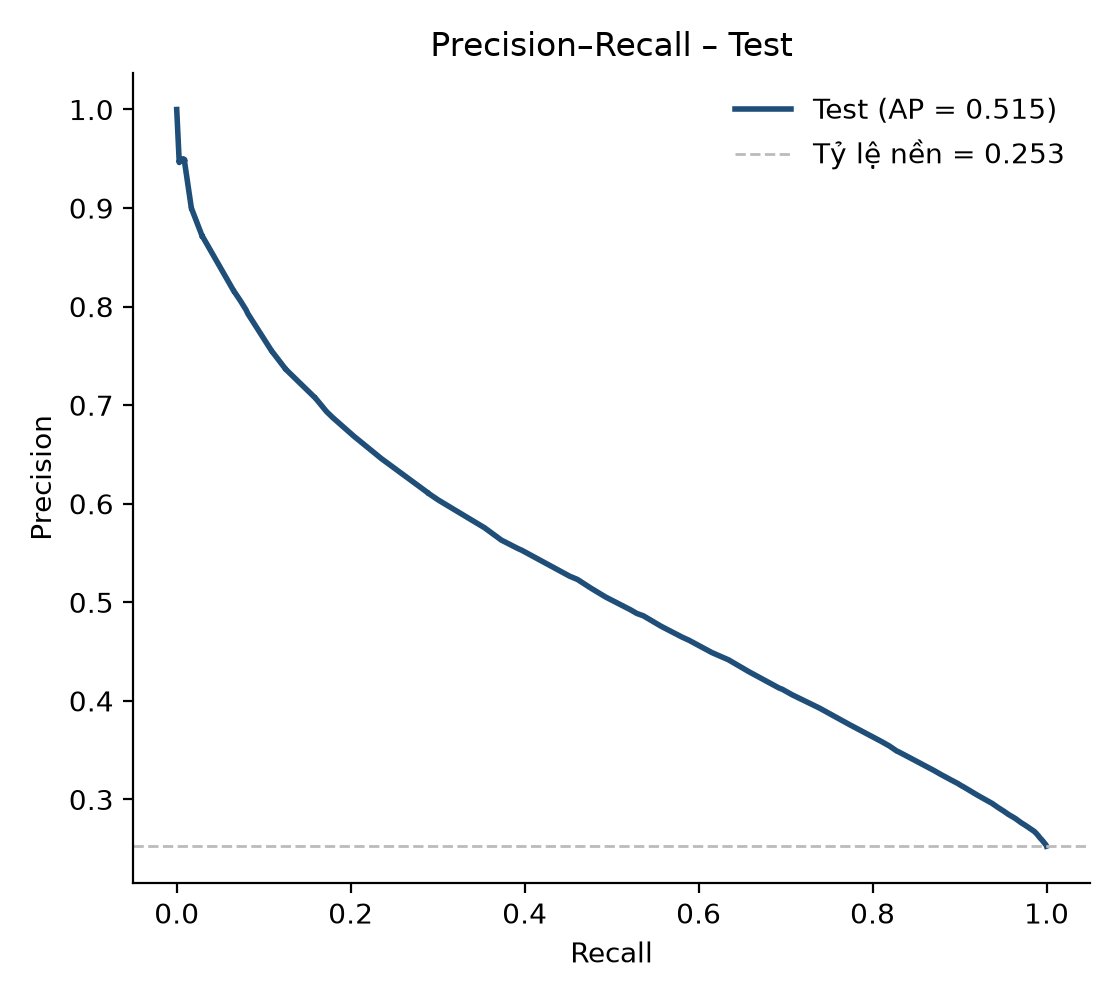

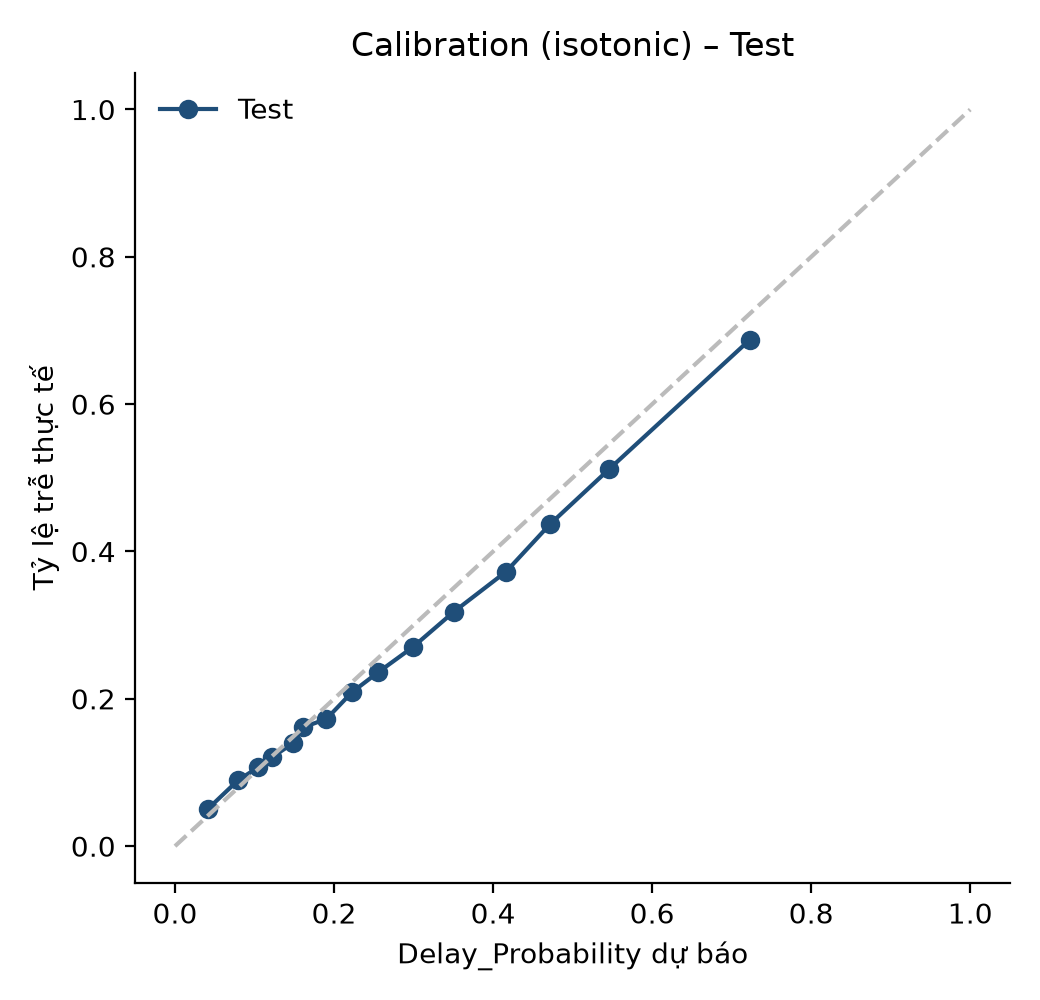

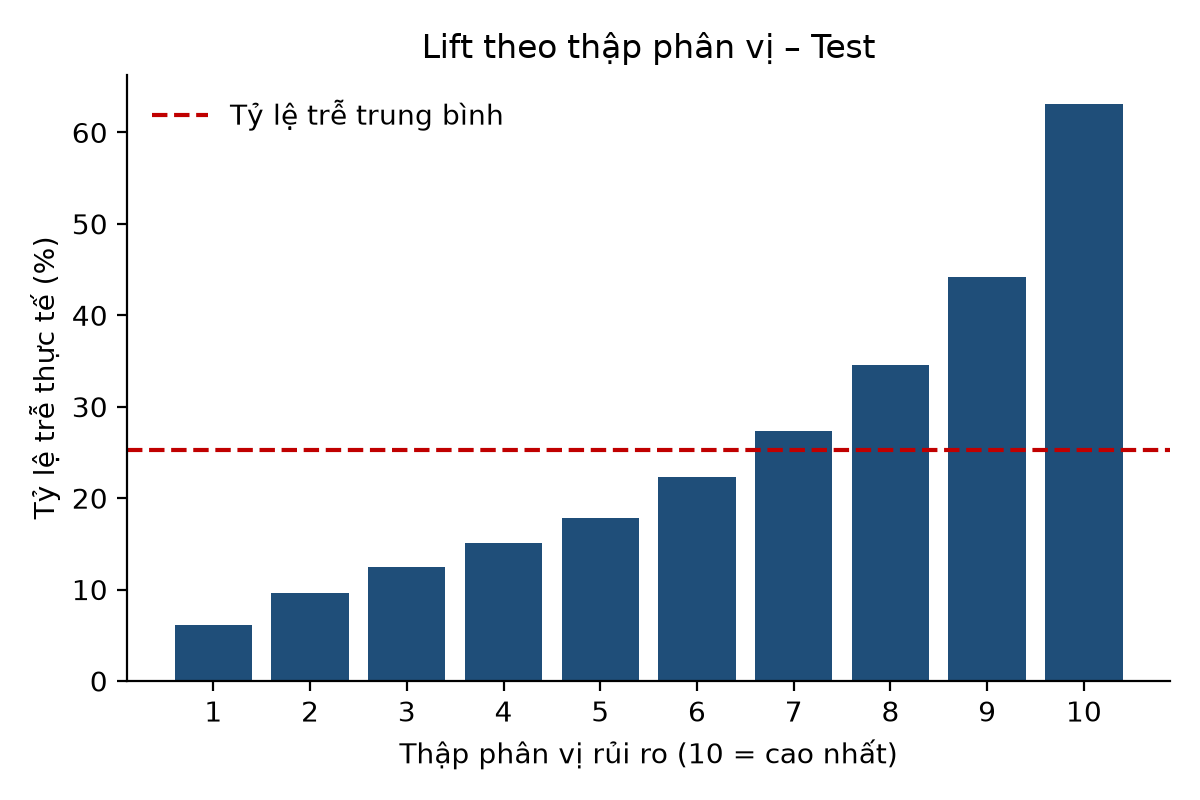

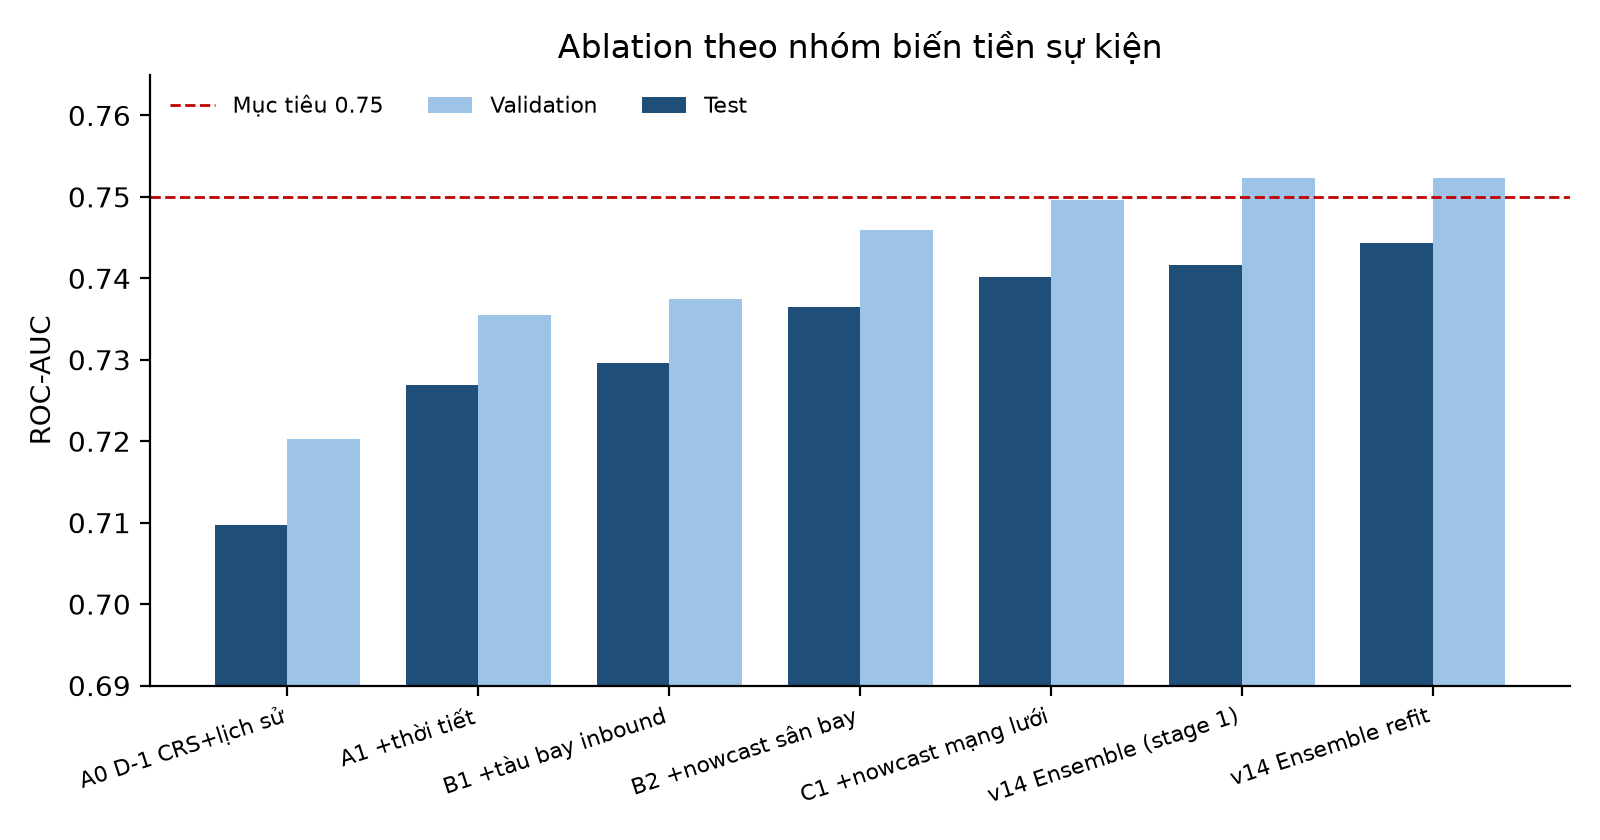

In [12]:
from IPython.display import Image, display
for f in ["roc_curve", "feature_importance", "confusion_matrix", "precision_recall_curve", "calibration_curve", "lift_decile", "ablation_auc"]:
    display(Image(filename=str(OUT_DIR / "figures" / f"{f}.png"), width=640))

In [13]:
imp = pd.read_csv(OUT_DIR / "feature_importance_v14.csv")
print(imp.groupby("family").gain_share.sum().sort_values(ascending=False).round(3))
imp.head(20).round(4)

family
Nowcast mạng lưới T-60       0.377
Lịch CRS & lịch sử ≤ D-1     0.363
Thời tiết ngày bay           0.126
Nowcast sân bay T-60         0.099
Lịch sử tàu bay (inbound)    0.036
Name: gain_share, dtype: float64


,feature,gain_share,family
0,car_dep_r15_120,0.0596,Nowcast mạng lưới T-60
1,reg_dep_r15_120,0.0356,Nowcast mạng lưới T-60
2,carrier_hour_30d,0.0219,Lịch CRS & lịch sử ≤ D-1
3,wx_precip_sum_both,0.0217,Thời tiết ngày bay
4,cr_dep_r15_360,0.0190,Nowcast mạng lưới T-60
5,o_backlog,0.0182,Nowcast sân bay T-60
6,origin_wx_weather_code_max,0.0168,Thời tiết ngày bay
7,car_dep_r15_360,0.0168,Nowcast mạng lưới T-60
8,car_dep_mean_120,0.0159,Nowcast mạng lưới T-60
9,wx_bad_hours_both,0.0158,Thời tiết ngày bay


## 5. Kiểm định Anti-Data Leakage độc lập

Bước 6–7: `audit_leakage.py` **không dùng lại SQL** sinh feature: tính lại bằng pandas brute-force số chuyến/tỷ lệ trễ theo hãng và toàn quốc trong 120 phút trước `T_pred` cho mẫu ngẫu nhiên, rồi so khớp; đồng thời kiểm tra danh sách biến cấm, cửa sổ lịch sử và cờ chặng inbound.

In [14]:
run_step("--from-step", "6")
audit = json.load(open(OUT_DIR / "leakage_audit_v14.json", encoding="utf-8"))
print(json.dumps(audit, ensure_ascii=False, indent=1))
assert audit["all_passed"], "AUDIT LEAKAGE THAT BAI"

[run ] step 6 audit_leakage


{
  "features": {
    "n_features": 280,
    "banned_found": [],
    "passed": true
  },
  "history_sql": {
    "windows_ending_1_preceding": 6,
    "windows_including_current_row": 0,
    "passed": true
  },
  "inbound": {
    "rows_with_inbound": 22505,
    "share_with_inbound": 0.01954672104948651,
    "delay_known_without_status_flag": 0,
    "passed": true
  },
  "network_bruteforce": {
    "sample": 400,
    "carrier_count_match": 1.0,
    "national_count_match": 1.0,
    "carrier_r15_max_abs_err": 2.6490953208835322e-08,
    "self_counted": 0,
    "future_events_counted": 0,
    "passed": true
  },
  "all_passed": true
}
[done] step 6 audit_leakage in 2s
[run ] step 7 variable_dictionary


wrote /home/ai1/bi-dss/rnd_8_4/delay_8_4/outputs/variable_dictionary_pre_event_v14.csv 280 features
Nhom
Nowcast mạng lưới    100
Lịch sử ≤ D-1         78
Lịch CRS              54
Thời tiết             24
Nowcast sân bay       17
Lịch sử tàu bay        7
[done] step 7 variable_dictionary in 0s
-> exit 0 sau 2s
{
 "features": {
  "n_features": 280,
  "banned_found": [],
  "passed": true
 },
 "history_sql": {
  "windows_ending_1_preceding": 6,
  "windows_including_current_row": 0,
  "passed": true
 },
 "inbound": {
  "rows_with_inbound": 22505,
  "share_with_inbound": 0.01954672104948651,
  "delay_known_without_status_flag": 0,
  "passed": true
 },
 "network_bruteforce": {
  "sample": 400,
  "carrier_count_match": 1.0,
  "national_count_match": 1.0,
  "carrier_r15_max_abs_err": 2.6490953208835322e-08,
  "self_counted": 0,
  "future_events_counted": 0,
  "passed": true
 },
 "all_passed": true
}


In [15]:
# Tu dien bien tien su kien (du 100% bien dua vao mo hinh) - buoc 7 cua pipeline
vd = pd.read_csv(OUT_DIR / "variable_dictionary_pre_event_v14.csv")
print(vd.groupby("Nhom").agg(so_bien=("Bien", "size"), gain_pct=("Gain_share_pct", "sum")).sort_values("gain_pct", ascending=False))
vd.sort_values("Gain_share_pct", ascending=False).head(15)

                   so_bien  gain_pct
Nhom                                
Nowcast mạng lưới      100    37.671
Lịch sử ≤ D-1           78    24.563
Thời tiết               24    12.553
Lịch CRS                54    11.760
Nowcast sân bay         17     9.855
Lịch sử tàu bay          7     3.600


,Bien,Nhom,Mo_ta,Kieu,Thoi_diem_biet,Nguon,Gain_share_pct
208,car_dep_r15_120,Nowcast mạng lưới,Tỷ lệ trễ ≥15' các chuyến đã cất cánh (cùng hã...,Số,Sự kiện mạng lưới đã xảy ra ≤ T_pred (đồng hồ ...,intermediate.int_flights_2022_2023 + múi giờ IANA,5.956
233,reg_dep_r15_120,Nowcast mạng lưới,Tỷ lệ trễ ≥15' các chuyến đã cất cánh (cùng vù...,Số,Sự kiện mạng lưới đã xảy ra ≤ T_pred (đồng hồ ...,intermediate.int_flights_2022_2023 + múi giờ IANA,3.560
101,carrier_hour_30d,Lịch sử ≤ D-1,Tỷ lệ trễ ≥15' theo hãng × giờ cất cánh KH tro...,Số,Cuối ngày D-1 (cửa sổ kết thúc 1 PRECEDING),marts.fact_flight (8.1),2.188
149,wx_precip_sum_both,Thời tiết,Tổng mưa hai đầu tuyến,Số,Dự báo ngày bay (proxy: quan trắc Open-Meteo),Open-Meteo archive API,2.169
261,cr_dep_r15_360,Nowcast mạng lưới,Tỷ lệ trễ ≥15' các chuyến đã cất cánh (cùng hã...,Số,Sự kiện mạng lưới đã xảy ra ≤ T_pred (đồng hồ ...,intermediate.int_flights_2022_2023 + múi giờ IANA,1.896
168,o_backlog,Nowcast sân bay,Số chuyến đến giờ đi KH nhưng chưa cất cánh tạ...,Số,Sự kiện tại sân bay đã xảy ra ≤ T_pred (giờ đị...,intermediate.int_flights_2022_2023,1.824
134,origin_wx_weather_code_max,Thời tiết,Mã thời tiết wmo nặng nhất tại sân bay đi,Số,Dự báo ngày bay (proxy: quan trắc Open-Meteo),Open-Meteo archive API,1.680
211,car_dep_r15_360,Nowcast mạng lưới,Tỷ lệ trễ ≥15' các chuyến đã cất cánh (cùng hã...,Số,Sự kiện mạng lưới đã xảy ra ≤ T_pred (đồng hồ ...,intermediate.int_flights_2022_2023 + múi giờ IANA,1.678
207,car_dep_mean_120,Nowcast mạng lưới,Trễ trung bình các chuyến đã cất cánh (cùng hã...,Số,Sự kiện mạng lưới đã xảy ra ≤ T_pred (đồng hồ ...,intermediate.int_flights_2022_2023 + múi giờ IANA,1.594
147,wx_bad_hours_both,Thời tiết,Tổng giờ thời tiết xấu tại sân bay đi + đến,Số,Dự báo ngày bay (proxy: quan trắc Open-Meteo),Open-Meteo archive API,1.583


## 6. Xuất `DSS_Flight_Prediction.csv` cho Power BI Trang 5

In [16]:
csv = OUT_DIR / "DSS_Flight_Prediction.csv"
pred = pd.read_csv(csv, nrows=None, usecols=["FlightKey", "Delay_Probability", "Priority_Tier", "DatasetSplit", "IsLabelled"])
assert len(pred) == 1_151_344 and pred.FlightKey.is_unique
assert pred.Delay_Probability.between(0, 1).all()
print(f"{len(pred):,} dong | Delay_Probability [{pred.Delay_Probability.min():.4f}, {pred.Delay_Probability.max():.4f}]")
print(pred.Priority_Tier.value_counts().sort_index().to_dict())
print("SHA-256:", S["csv"]["sha256"], "|", f"{csv.stat().st_size/1e6:.1f} MB")
display(pd.read_csv(OUT_DIR / "DSS_Priority_Tier.csv"))
pd.read_csv(OUT_DIR / "DSS_Flight_Prediction_sample.csv").head(8)

1,151,344 dong | Delay_Probability [0.0010, 0.9990]
{'P1': 210955, 'P2': 175855, 'P3': 364812, 'P4': 399722}
SHA-256: 2d13dfc521dcc17a34059e7c69fa6cc6391943955a9312f81bb358b45b5e669d | 140.1 MB


,Priority_Tier,Tier_Name,Recommended_Action,Sort_Order,Decision_Threshold,Prediction_Horizon,Model_Version
0,P1,Rủi ro cao · Tác động cao,"Can thiệp ngay: bố trí tàu/tổ bay dự phòng, ưu...",1,0.25,T-60 phút,v14-ensemble-xgb-lgb-isotonic
1,P2,Rủi ro cao · Tác động thấp,"Theo dõi sát: cảnh báo OCC, chuẩn bị phương án...",2,0.25,T-60 phút,v14-ensemble-xgb-lgb-isotonic
2,P3,Rủi ro thấp · Tác động cao,"Giám sát định kỳ: chuyến tác động lớn, rủi ro ...",3,0.25,T-60 phút,v14-ensemble-xgb-lgb-isotonic
3,P4,Rủi ro thấp · Tác động thấp,Vận hành bình thường,4,0.25,T-60 phút,v14-ensemble-xgb-lgb-isotonic


,FlightKey,DateKey,CarrierKey,OriginAirportKey,DestAirportKey,RouteKey,FlightNumber,FlightDate,CRSDepTime,ScheduledDepHour,...,Delay_Probability,Predicted_Delayed15,Risk_Level,Impact_Score,Priority_Score,Priority_Tier,Actual_Delayed15,DatasetSplit,IsLabelled,RouteName
0,1,20220101,1,23,162,224,4632,2022-01-01,1620,16,...,0.3090,1,Trung bình,0.5740,24.32,P1,1.0,train,1,ATL-HPN
1,2,20220101,1,222,204,3968,4640,2022-01-01,1140,11,...,0.2892,1,Trung bình,0.1249,16.26,P2,1.0,train,1,MEM-LGA
2,3,20220101,1,1,23,1,4644,2022-01-01,636,6,...,0.1215,0,Thấp,0.0717,6.51,P4,0.0,train,1,ABE-ATL
3,4,20220101,1,184,105,3164,4654,2022-01-01,1500,15,...,0.1971,0,Thấp,0.2609,12.43,P3,NaN,train,0,JFK-DTW
4,5,20220101,1,68,204,1039,4657,2022-01-01,1110,11,...,0.1537,0,Thấp,0.0960,8.42,P4,0.0,train,1,CHS-LGA
5,6,20220101,1,204,229,3592,4666,2022-01-01,1459,14,...,0.4180,1,Trung bình,0.3344,27.89,P1,1.0,train,1,LGA-MKE
6,7,20220101,1,143,105,2518,4682,2022-01-01,900,9,...,0.1102,0,Thấp,0.0315,5.68,P4,0.0,train,1,GRB-DTW
7,8,20220101,1,23,362,309,4685,2022-01-01,2100,21,...,0.2993,1,Trung bình,0.5175,22.71,P1,NaN,train,0,ATL-VLD


In [17]:
if IN_COLAB:  # tai len Drive cho nhom Power BI
    os.makedirs(DRIVE_DIR, exist_ok=True)
    for f in ["DSS_Flight_Prediction.csv", "DSS_Priority_Tier.csv", "model_summary_v14.json", "leakage_audit_v14.json"]:
        shutil.copy(OUT_DIR / f, Path(DRIVE_DIR) / f)
    print("Da copy len", DRIVE_DIR)

## 7. Phản biện & giới hạn (model card rút gọn)

1. **Mục tiêu ROC-AUC ≥ 0,75**: đạt trên validation; trên test (07–08/2023) thấp hơn khoảng 0,01, nhất quán ở mọi thí nghiệm → do **dịch phân phối mùa hè** (tháng 7 đạt ≥ 0,75, tháng 8 giảm). Không tinh chỉnh theo test để "chạm" ngưỡng.
2. **Trần thông tin của dữ liệu mẫu 10%**: không có `TAIL_NUM`, chuỗi quay vòng tàu bay chỉ nối được ~2% chuyến; các tín hiệu nowcast bị loãng ~10 lần so với dữ liệu BTS đầy đủ.
3. **Thời tiết** là giá trị quan trắc của ngày bay (Open-Meteo archive) — giả định "dự báo hoàn hảo"; ablation cho thấy nhóm này đóng góp ~+0,017 AUC. Triển khai thật cần thay bằng bản tin dự báo (Open-Meteo Historical Forecast / NOAA).
4. **Hiệu chỉnh**: xác suất isotonic, kẹp [0,001; 0,999]; train/validation rows trong CSV là dự báo trong mẫu (in-sample) — chỉ dùng kỳ test để đánh giá trên dashboard.
5. **Vận hành**: theo dõi AUC theo tháng trên Trang 5, retrain định kỳ (drift tháng 8).

In [18]:
manifest = {"generated_at": time.strftime("%Y-%m-%d %H:%M:%S"), "env": S["environment"],
            "inputs": {"warehouse.duckdb_bytes": DB_PATH.stat().st_size},
            "outputs": {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted((OUT_DIR).glob("*.csv"))}}
json.dump(manifest, open(OUT_DIR / "run_manifest_v14.json", "w"), indent=1)
manifest

{'generated_at': '2026-11-08 22:46:50',
 'env': {'python': '3.11.18',
  'platform': 'Linux-5.15.0-139-generic-x86_64-with-glibc2.31',
  'device': 'cuda',
  'xgboost': '3.2.0',
  'lightgbm': '4.7.0',
  'sklearn': '1.9.1'},
 'inputs': {'warehouse.duckdb_bytes': 569389056},
 'outputs': {'DSS_Flight_Prediction.csv': '2d13dfc521dcc17a34059e7c69fa6cc6391943955a9312f81bb358b45b5e669d',
  'DSS_Flight_Prediction_sample.csv': '77b6e4b73450d79df428b0b952a25615dd3c0b9dd5495aa3d9c1c93e2d61c1a9',
  'DSS_Priority_Tier.csv': '0bb8b4810f16ad8b8db395067ea9244e2d09b2ea6aa60e41a04ff0022d6517ff',
  'feature_importance_v14.csv': '22e52c11e697507a2c3d07932547e3ab75e8e675d9ded6aeb458654cbf348269',
  'variable_dictionary_pre_event_v14.csv': 'db6719115d4ab3aa873c22c6eeb7716c759a00ee14094ae5be57f731b912d840'}}